In [ ]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import seaborn as sns

from complex_networks_laboratories.graph import (
    are_graphs_equal,
    graph_from_incidence_matrix,
    load_graph,
)

# Laboratorium 2

In [13]:
graph = load_graph()

### Wygenerować macierz sąsiedztwa dla badanego grafu

Macierz ta reprezentuje połączenia między wierzchołkami. 

Wartości niezerowe oznaczają, ze istnieje dla nich krawędź. 

Jest to macierz kwadratowa.

Sanity check: w macierzy sąsiedztwa suma elementów powinna wynosić 2 * liczba rekodów w graph.edges.

In [ ]:
nodes_len = len(graph.nodes)
print(f"Liczba wierchołków {nodes_len}")
adjacency_matrix = np.zeros(shape=(nodes_len, nodes_len))
print(f"Wymiary macierzy: {adjacency_matrix.shape}")
for edge in graph.edges:
    u, v = edge[0], edge[1]
    adjacency_matrix[u][v] += 1
    adjacency_matrix[v][u] += 1


edges = list(graph.edges)
u, v = edges[0][:2]
print("Suma elementów == 2*|E|:", adjacency_matrix.sum() == 2 * len(graph.edges))

Liczba wierchołków 1511
Wymiary macierzy: (1511, 1511)
Suma elementów == 2*|E|: True


### Wygenerować macierz incydencji dla badanego grafu

[Graph Theory: How to Create an Incidence Matrix](https://www.youtube.com/watch?v=h2WMciVn7CI)

Budowa: wiersze reprezentują dany wierzchołek, natomiast kolumna daną krawędź.

Po co: ciekawe własności - suma wartości w wierszu jest stopniem danego wierzchołka, suma wartości w kolumnie zawsze wynosi 2 (gdy istnieje jeden rodzaj krawędzi, z wartością 1 gdy w danym kierunku wartość istnieje dla grafu nieskierowanego).

Mnozenie A*A^T (w przypadku grafu nieskierowanego) da macierz sąsiedztwa, na której przekątnej są wartości stopnia danego wierzchołka, nie zaleznie od konwencji kolejności kolumn.

In [ ]:
nodes_len = len(graph.nodes)
edges_len = len(graph.edges)
incidence_matrix = np.zeros(shape=(nodes_len, edges_len))
for edge_id, edge in enumerate(graph.edges):
    u, v = edge[0], edge[1]
    incidence_matrix[u][edge_id] += 1
    incidence_matrix[v][edge_id] += 1

A = incidence_matrix

transformed_adjacency = A @ A.T
transformed_adjacency_no_diag = transformed_adjacency.copy()

for i in range(len(transformed_adjacency)):
    transformed_adjacency_no_diag[i][i] = 0
is_transform_adjacent = np.array_equal(adjacency_matrix, transformed_adjacency_no_diag)

print(f"Czy transpozycja dała macierz sąsiedztwa (z diagonalem stopni): {is_transform_adjacent}")

Czy transpozycja dała macierz sąsiedztwa (z diagonalem stopni): True


### Wczytać obie reprezentacje do programu i odtworzyć graf dla obu macierzy.

In [ ]:
graph_from_adj = nx.from_numpy_array(adjacency_matrix)
graph_from_inc = graph_from_incidence_matrix(incidence_matrix)
is_valid_adj = are_graphs_equal(graph_from_adj, graph, False)
is_valid_inc = are_graphs_equal(graph_from_inc, graph, False)


print(f"Czy graf jest taki sam (macierz sąsiedztwa, skip wag): {is_valid_adj}")
print(f"Czy graf jest taki sam (macierz incydencji, skip wag): {is_valid_inc}")

Czy graf jest taki sam (macierz sąsiedztwa, skip wag): True
Czy graf jest taki sam (macierz incydencji, skip wag): True


### Przedstawić graf w postaci graficznej przy pomocy narzędzi z np. networkx.

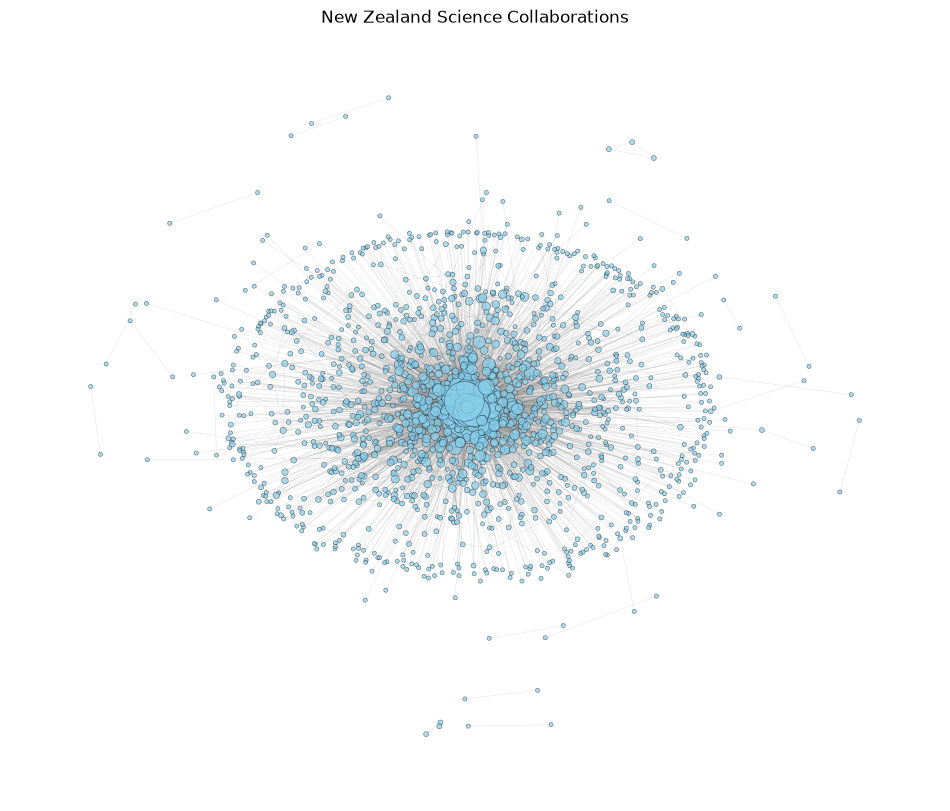

In [17]:
degrees = dict(graph.degree())
node_sizes = [degrees[node] * 4 + 5 for node in graph.nodes]

plt.figure(figsize=(12, 10))

pos = nx.spring_layout(graph, seed=42, k=0.15)
nx.draw_networkx_nodes(
    graph,
    pos,
    node_size=node_sizes,
    node_color="skyblue",
    alpha=0.7,
    edgecolors="black",
    linewidths=0.3,
)
nx.draw_networkx_edges(graph, pos, width=0.4, alpha=0.2, edge_color="gray")

plt.title("New Zealand Science Collaborations")
plt.axis("off")
plt.show()

### Wyznaczyć i zinterpretować:
- rozkład stopni wierzchołków,
- gęstość grafu,
- średnicę grafu.

### Rozkład stopni wierzchołków

Skala log-log pokazuje, ze rozkład potęgowy.

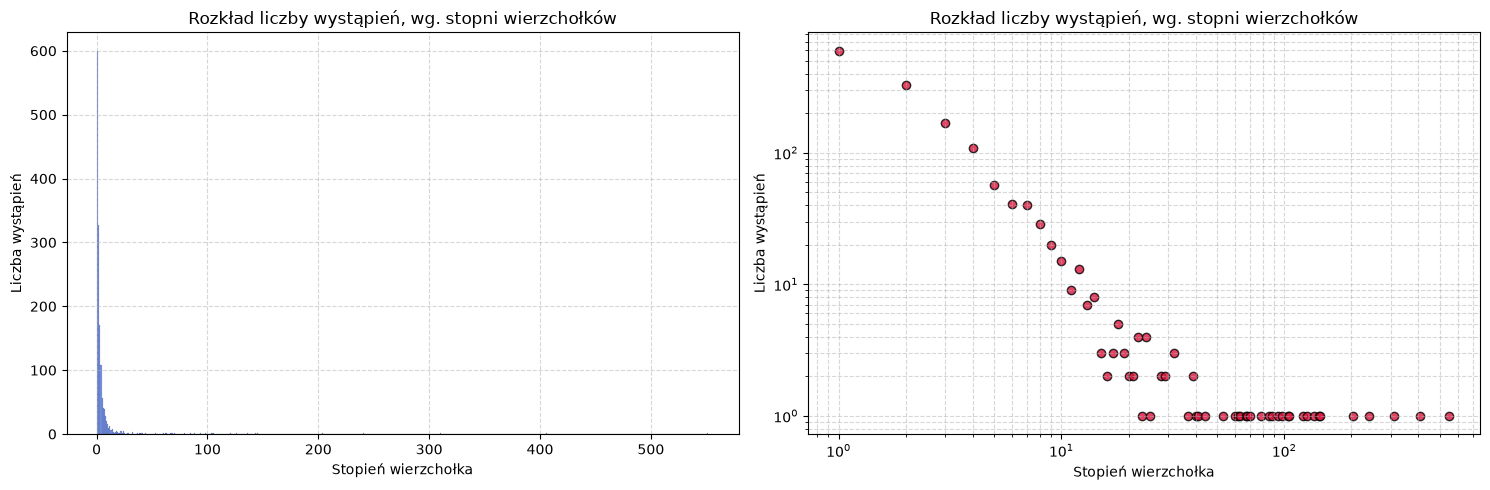

In [23]:
AA_T = incidence_matrix @ incidence_matrix.T
degrees = np.diag(AA_T).astype(int)

unique_degrees, counts = np.unique(degrees, return_counts=True)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(
    degrees,
    discrete=True,
    ax=axes[0],
    color="royalblue",
    edgecolor="black",
    alpha=0.7,
)
axes[0].set_title("Rozkład liczby wystąpień, wg. stopni wierzchołków", fontsize=12)
axes[0].set_xlabel("Stopień wierzchołka")
axes[0].set_ylabel("Liczba wystąpień")
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].scatter(unique_degrees, counts, color="crimson", alpha=0.8, edgecolors="black")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("Rozkład liczby wystąpień, wg. stopni wierzchołków", fontsize=12)
axes[1].set_xlabel("Stopień wierzchołka")
axes[1].set_ylabel("Liczba wystąpień")
axes[1].grid(True, which="both", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### Gęstość grafu

Wzór na gęstość grafu: $$d = E / \frac{V(V-1)}{2}$$ gdzie:

- E - liczba krawędzi,
- V - liczba wierzchołków

In [26]:
density_prebuilt = nx.density(graph)
nodes_count = len(graph.nodes)
edges_count = len(graph.edges)
density_manual = 2 * edges_count / (nodes_count * (nodes_count - 1))
print(f"Czy wzór zlicza prawidłowo: {density_prebuilt}, {density_manual}")

Czy wzór zlicza prawidłowo: 0.0037456006942466064, 0.0037456006942466064


Wnioski:
- graf rzadki,
- macierz sąsiedztwa to marnotrastwo zasobów (większość komórek zerowa)

### Średnica

- najdłuzsza z najkrótszych ściezek w grafie (między dowolnymi dwoma punktami),
- wymaga grafu spójnego

Mój graf nie jest spójny, więc wykorzystam największy spójny podzbiór.

In [28]:
largest_connection = max(nx.connected_components(graph), key=len)
largest_subgraph = graph.subgraph(largest_connection)
diameter = nx.diameter(largest_subgraph)
print(f"Średnica dla grafu ({largest_subgraph}) wynosi: {diameter}")

Średnica dla grafu (Graph with 1463 nodes and 4246 edges) wynosi: 6


Wnioski:
- mimo sporego i rzadkiego grafu, średnica wydaje się być relatywnie niska (6),
- [Six degrees of separation](https://en.wikipedia.org/wiki/Six_degrees_of_separation)

### Wskazać, jakie informacje o strukturze sieci można uzyskać wyłącznie na podstawie jej wizualizacji. 
Przygotować interpretację tego, co można wywnioskować z postaci graficznej.

#### Niespójność sieci
Łatwo zaobserwować nieliczne odcięte wierzchołki,
#### Istnienie hubów/rozkład potęgowy
Występuje skrajne zróżnicowanie rozmiarów węzłów: zaledwie kilka „wielkich” wierzchołków skupia wokół siebie gęste wiązki połączeń, natomiast dominująca większość to „małe” wierzchołki o niskim stopniu 1–2. 

#### Rzadkość grafu
Łatwo zaobserować punkty z nielicznymi mozliwymi połączeniami.
